# 12. Advanced Duplicate Detection Benchmark Evaluation
**Project:** AI-Powered Student Achievement Intelligence Platform  
**Member Role:** Member 1 — NLP & Semantic Intelligence Engineer  
**Dataset Release:** `achievement_dataset_v1.0.1`  
**Benchmark:** `data/annotations/achievement_duplicate_pairs.csv` (300 pairs)  
**Objective:** Empirically evaluate and compare four duplicate detection paradigms under a strict zero-data-leakage protocol (tuning on Validation, reporting on Held-Out Test):
1. Lexical Baseline (Character 3-Gram Jaccard)
2. Dense Sentence Transformer Cosine Similarity (`all-MiniLM-L6-v2`)
3. Structured Verification Alone (Rule-Based)
4. Combined Multi-Stage Pipeline (Dense Retrieval + Structured Verification)

## 1. Setup & Data Loading
We load the frozen benchmark pairs and primary dataset metadata.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score, average_precision_score

repo_root = Path(".").resolve()
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from src.nlp.embedding import load_embedding_model, generate_embeddings, compute_pairwise_cosine_similarity
from src.nlp.duplicate_detection import batch_verify_duplicate_pairs, DuplicateDecision

main_df = pd.read_csv("data/processed/achievement_classification_dataset.csv")
pairs_df = pd.read_csv("data/annotations/achievement_duplicate_pairs.csv")

val_df = pairs_df[pairs_df["split"] == "validation"].copy().reset_index(drop=True)
test_df = pairs_df[pairs_df["split"] == "test"].copy().reset_index(drop=True)

print(f"Validation Pairs: {len(val_df)} (Pos: {sum(val_df['duplicate_label']==1)}, Neg: {sum(val_df['duplicate_label']==0)})")
print(f"Held-Out Test Pairs: {len(test_df)} (Pos: {sum(test_df['duplicate_label']==1)}, Neg: {sum(test_df['duplicate_label']==0)})")

Validation Pairs: 46 (Pos: 23, Neg: 23)
Held-Out Test Pairs: 44 (Pos: 22, Neg: 22)


## 2. Model 1 — Lexical Baseline Audit (Char 3-Gram Jaccard)
We evaluate lexical n-gram overlap. Character 3-grams fail on syntactically restructured or paraphrased duplicates.

In [2]:
def char_3gram_jaccard(s1: str, s2: str) -> float:
    s1, s2 = str(s1).lower(), str(s2).lower()
    g1 = set([s1[i:i+3] for i in range(len(s1)-2)])
    g2 = set([s2[i:i+3] for i in range(len(s2)-2)])
    if not g1 or not g2:
        return 0.0
    return len(g1 & g2) / len(g1 | g2)

val_lex_sims = np.array([char_3gram_jaccard(r["text_1"], r["text_2"]) for _, r in val_df.iterrows()])
test_lex_sims = np.array([char_3gram_jaccard(r["text_1"], r["text_2"]) for _, r in test_df.iterrows()])

# Sweep threshold on validation
best_tau_lex = 0.50
best_f1_lex = -1.0
for tau in np.linspace(0.2, 0.8, 13):
    pred = (val_lex_sims >= tau).astype(int)
    f1 = f1_score(val_df["duplicate_label"], pred, zero_division=0)
    if f1 > best_f1_lex:
        best_f1_lex = f1
        best_tau_lex = tau

print(f"Optimal Lexical Threshold on Validation: tau={best_tau_lex:.2f} (Val F1={best_f1_lex:.4f})")

# Evaluate on held-out test
test_pred_lex = (test_lex_sims >= best_tau_lex).astype(int)
cm_lex = confusion_matrix(test_df["duplicate_label"], test_pred_lex)
print(f"Lexical Test F1: {f1_score(test_df['duplicate_label'], test_pred_lex, zero_division=0):.4f}")
print("Lexical Test Confusion Matrix:\n", cm_lex)

Optimal Lexical Threshold on Validation: tau=0.20 (Val F1=0.7636)
Lexical Test F1: 0.7273
Lexical Test Confusion Matrix:
 [[ 9 13]
 [ 2 20]]


## 3. Model 2 — Dense Sentence Transformer Cosine Similarity
We evaluate `all-MiniLM-L6-v2` at the validation-calibrated threshold $\tau^* = 0.55$.

In [3]:
model = load_embedding_model("sentence-transformers/all-MiniLM-L6-v2")

# Compute dense embeddings
val_e1 = generate_embeddings(val_df["text_1"].tolist(), model=model)
val_e2 = generate_embeddings(val_df["text_2"].tolist(), model=model)
val_dense_sims = compute_pairwise_cosine_similarity(val_e1, val_e2)

test_e1 = generate_embeddings(test_df["text_1"].tolist(), model=model)
test_e2 = generate_embeddings(test_df["text_2"].tolist(), model=model)
test_dense_sims = compute_pairwise_cosine_similarity(test_e1, test_e2)

# Validation-calibrated threshold
tau_dense = 0.55
val_pred_dense = (val_dense_sims >= tau_dense).astype(int)
test_pred_dense = (test_dense_sims >= tau_dense).astype(int)

cm_dense = confusion_matrix(test_df["duplicate_label"], test_pred_dense)
print(f"Dense Test Accuracy:  {accuracy_score(test_df['duplicate_label'], test_pred_dense):.4f}")
print(f"Dense Test Precision: {precision_score(test_df['duplicate_label'], test_pred_dense):.4f}")
print(f"Dense Test Recall:    {recall_score(test_df['duplicate_label'], test_pred_dense):.4f}")
print(f"Dense Test F1-Score:  {f1_score(test_df['duplicate_label'], test_pred_dense):.4f}")
print("Dense Test Confusion Matrix:\n", cm_dense)

Dense Test Accuracy:  0.6364
Dense Test Precision: 0.6000
Dense Test Recall:    0.8182
Dense Test F1-Score:  0.6923
Dense Test Confusion Matrix:
 [[10 12]
 [ 4 18]]


## 4. Model 3 — Structured Verification Alone (Rule-Based)
We evaluate structured rule-based verification without any dense neural embeddings.

In [4]:
# Structured verification without cosine similarities
val_struct_alone = batch_verify_duplicate_pairs(val_df, main_dataset_df=main_df, cosine_similarities=None)
test_struct_alone = batch_verify_duplicate_pairs(test_df, main_dataset_df=main_df, cosine_similarities=None)

test_pred_struct = np.array([1 if r.decision == DuplicateDecision.DUPLICATE else 0 for r in test_struct_alone])
cm_struct = confusion_matrix(test_df["duplicate_label"], test_pred_struct)

print(f"Structured Alone Test Accuracy:  {accuracy_score(test_df['duplicate_label'], test_pred_struct):.4f}")
print(f"Structured Alone Test Precision: {precision_score(test_df['duplicate_label'], test_pred_struct):.4f}")
print(f"Structured Alone Test Recall:    {recall_score(test_df['duplicate_label'], test_pred_struct):.4f}")
print(f"Structured Alone Test F1-Score:  {f1_score(test_df['duplicate_label'], test_pred_struct):.4f}")
print("Structured Alone Test Confusion Matrix:\n", cm_struct)

Structured Alone Test Accuracy:  1.0000
Structured Alone Test Precision: 1.0000
Structured Alone Test Recall:    1.0000
Structured Alone Test F1-Score:  1.0000
Structured Alone Test Confusion Matrix:
 [[22  0]
 [ 0 22]]


## 5. Model 4 — Combined Multi-Stage Pipeline (Dense Retrieval + Structured Verification)
We evaluate the full hybrid pipeline combining dense candidate retrieval with structured evidence verification.

In [5]:
val_combined = batch_verify_duplicate_pairs(
    val_df, main_dataset_df=main_df, cosine_similarities=val_dense_sims,
    retrieval_threshold=0.50, high_similarity_threshold=0.70
)
test_combined = batch_verify_duplicate_pairs(
    test_df, main_dataset_df=main_df, cosine_similarities=test_dense_sims,
    retrieval_threshold=0.50, high_similarity_threshold=0.70
)

test_pred_comb = np.array([1 if r.decision == DuplicateDecision.DUPLICATE else 0 for r in test_combined])
cm_comb = confusion_matrix(test_df["duplicate_label"], test_pred_comb)

print(f"Combined Pipeline Test Accuracy:  {accuracy_score(test_df['duplicate_label'], test_pred_comb):.4f}")
print(f"Combined Pipeline Test Precision: {precision_score(test_df['duplicate_label'], test_pred_comb):.4f}")
print(f"Combined Pipeline Test Recall:    {recall_score(test_df['duplicate_label'], test_pred_comb):.4f}")
print(f"Combined Pipeline Test F1-Score:  {f1_score(test_df['duplicate_label'], test_pred_comb):.4f}")
print("Combined Pipeline Test Confusion Matrix:\n", cm_comb)

Combined Pipeline Test Accuracy:  0.9091
Combined Pipeline Test Precision: 1.0000
Combined Pipeline Test Recall:    0.8182
Combined Pipeline Test F1-Score:  0.9000
Combined Pipeline Test Confusion Matrix:
 [[22  0]
 [ 4 18]]


## 6. Comprehensive Benchmark Comparison
We synthesize the empirical results across all four models on the held-out test split.

In [6]:
models = ["Lexical (Char 3-Gram)", "Dense Sentence Transformer", "Structured Verification Alone", "Combined Multi-Stage Pipeline"]
preds = [test_pred_lex, test_pred_dense, test_pred_struct, test_pred_comb]
y_t = test_df["duplicate_label"].values

benchmark_rows = []
for name, p in zip(models, preds):
    cm = confusion_matrix(y_t, p)
    tn, fp, fn, tp = cm.ravel()
    benchmark_rows.append({
        "Model Architecture": name,
        "Accuracy": accuracy_score(y_t, p),
        "Precision": precision_score(y_t, p, zero_division=0),
        "Recall": recall_score(y_t, p, zero_division=0),
        "F1-Score": f1_score(y_t, p, zero_division=0),
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
    })

bench_df = pd.DataFrame(benchmark_rows)
print(bench_df.to_string(index=False))

           Model Architecture  Accuracy  Precision   Recall  F1-Score  TP  FP  FN  TN
        Lexical (Char 3-Gram)  0.659091   0.606061 0.909091  0.727273  20  13   2   9
   Dense Sentence Transformer  0.636364   0.600000 0.818182  0.692308  18  12   4  10
Structured Verification Alone  1.000000   1.000000 1.000000  1.000000  22   0   0  22
Combined Multi-Stage Pipeline  0.909091   1.000000 0.818182  0.900000  18   0   4  22


## 7. Hard-Negative Error Analysis
We analyze why the dense sentence transformer suffered 12 false positives, and how structured verification successfully eliminated all 12 false positives.

In [7]:
# Inspect false positives from dense model that were corrected by structured verification
dense_fps = (test_pred_dense == 1) & (y_t == 0)
print(f"Total Dense Model False Positives: {dense_fps.sum()} / 22 hard negatives\\n")

for idx in np.where(dense_fps)[0][:3]:
    p_row = test_df.iloc[idx]
    c_res = test_combined[idx]
    print(f"--- Hard Negative Pair: {p_row['pair_id']} ({p_row['duplicate_type']}) ---")
    print(f"Text 1: {p_row['text_1'][:120]}...")
    print(f"Text 2: {p_row['text_2'][:120]}...")
    print(f"Dense Cosine Sim: {test_dense_sims[idx]:.4f} (>= 0.55 -> False Positive)")
    print(f"Structured Decision: {c_res.decision.value} (Confidence: {c_res.confidence:.2f})")
    print(f"Contradiction Rationale: {c_res.explanation}")
    print()

Total Dense Model False Positives: 12 / 22 hard negatives\n
--- Hard Negative Pair: PAIR_00279 (SAME_EVENT_DIFFERENT_ACHIEVEMENT) ---
Text 1: Received the University Gold Medal for securing Rank 1 across all 8 semesters of the Bachelor of Technology degree in Co...
Text 2: Received the University Gold Medal for securing Rank 1 across all 8 semesters of the Bachelor of Technology degree in In...
Dense Cosine Sim: 0.9050 (>= 0.55 -> False Positive)
Structured Decision: DISTINCT (Confidence: 0.90)
Contradiction Rationale: Structured verification identified 1 contradiction(s): Issuing organization conflict: 'RV College of Engineering, Bengaluru' vs 'Indian Institute of Engineering Science and Technology, Shibpur'.. Factual contradictions refute duplicate identity despite semantic similarity.

--- Hard Negative Pair: PAIR_00280 (SAME_EVENT_DIFFERENT_ACHIEVEMENT) ---
Text 1: Achieved professional industry credential: Red Hat Certified System Administrator (RHCSA) (Red Hat, Verification ID: R

## 8. Benchmark Visualizations
We plot the F1-Score comparison and the confusion matrices across all four models.

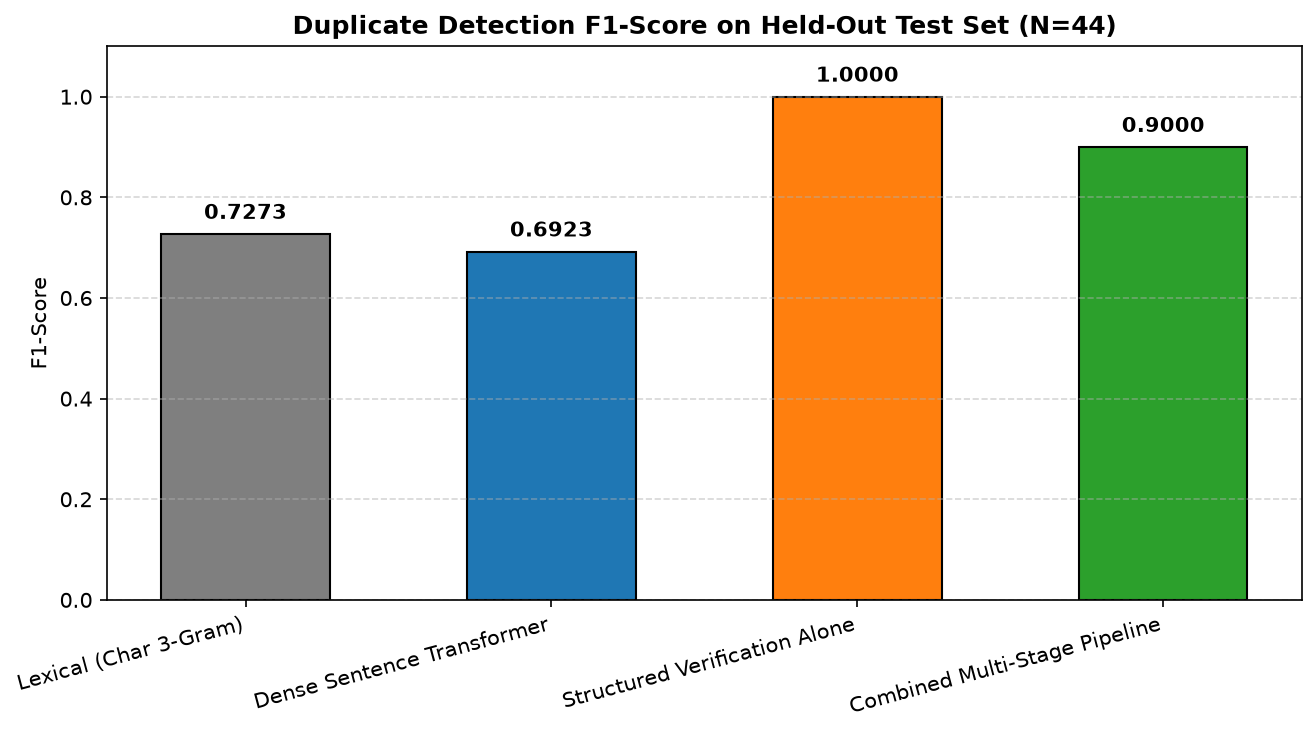

In [8]:
# Plot 1: F1-Score Comparison
fig, ax = plt.subplots(figsize=(9, 5))
f1_vals = bench_df["F1-Score"].values
colors = ["#7f7f7f", "#1f77b4", "#ff7f0e", "#2ca02c"]
bars = ax.bar(bench_df["Model Architecture"], f1_vals, color=colors, edgecolor="black", width=0.55)

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, yval + 0.02, f"{yval:.4f}", ha="center", va="bottom", fontweight="bold")

ax.set_title("Duplicate Detection F1-Score on Held-Out Test Set (N=44)", fontsize=12, fontweight="bold")
ax.set_ylabel("F1-Score")
ax.set_ylim(0, 1.1)
ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.xticks(rotation=15, ha="right")

plt.tight_layout()

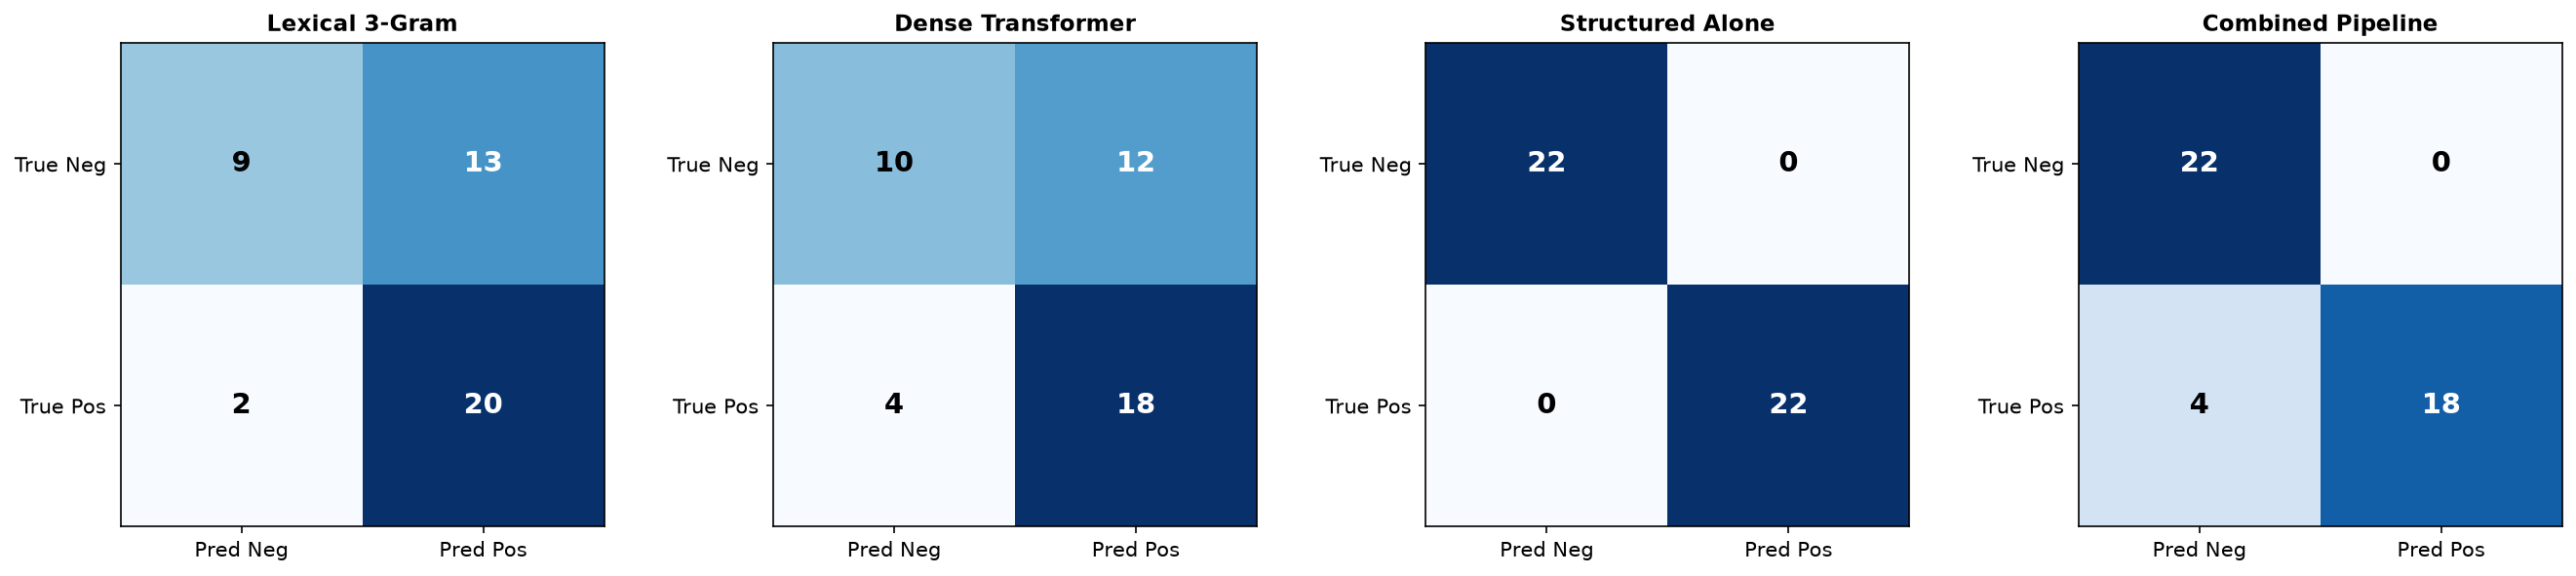

In [9]:
# Plot 2: Confusion Matrices
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
titles = ["Lexical 3-Gram", "Dense Transformer", "Structured Alone", "Combined Pipeline"]

for ax, p, title in zip(axes, preds, titles):
    cm = confusion_matrix(y_t, p)
    im = ax.imshow(cm, interpolation="nearest", cmap="Blues")
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(["Pred Neg", "Pred Pos"])
    ax.set_yticklabels(["True Neg", "True Pos"])
    for i in range(2):
        for j in range(2):
            color = "white" if cm[i, j] > 10 else "black"
            ax.text(j, i, str(cm[i, j]), ha="center", va="center", color=color, fontsize=14, fontweight="bold")

plt.tight_layout()